# Lab01 - sprint 1
## Химические показатели красного вина: анализ трёх случайных величин
**Авторы: Самоховец Анна (ИСУ 504789), Василиса Сергеева (ИСУ 502556), Панова Екатерина (ИСУ 502874)**

**Инфохимия · Лабораторная работа 01 · Спринт 1**

Расчёты и пояснения подготовлены с помощью ИИ. Математическая часть опирается на источники из списка литературы.

**Вопрос исследования:** как распределены pH, остаточный сахар и содержание спирта?

Работа включает только часть для инфохимии. Дополнительный блок КТвД, marimo и интерфейс генератора не включены.

**Как запустить:** открыть в Jupyter / Google Colab и выполнить все ячейки сверху вниз. Данные встроены в файл, интернет для их загрузки не нужен. Нужны `numpy`, `pandas`, `scipy`, `matplotlib`. Выводы и графики уже сохранены.

**Навигация:** [данные](#data) · [pH](#rv1) · [сахар](#rv2) · [спирт](#rv3) · [зависимости](#dependence) · [итог 1](#resume1) · [литература](#references).




<a id="data"></a>
## Данные и план исследования
Используется **Wine Quality, красное Vinho Verde**, UCI, DOI: [10.24432/C56S3T](https://doi.org/10.24432/C56S3T), авторы P. Cortez, A. Cerdeira, F. Almeida, T. Matos, J. Reis (2009). Лицензия CC BY 4.0. Источник: [страница набора](https://archive.ics.uci.edu/dataset/186/wine+quality). Исходный файл `winequality-red.csv`, 1599 строк, 12 столбцов.

| Величина | Столбец | Единицы | Смысл |
|---|---|---|---|
| pH | pH | безразмерная | характеристика кислотности |
| Остаточный сахар | residual sugar | г/дм³ = г/л | массовая концентрация сахара |
| Спирт | alcohol | % об. | объёмное содержание этанола |

Единицы сахара и спирта проверены по [описанию учебного набора R. Nugent, CMU](https://www.stat.cmu.edu/~rnugent/PCMI2016/WineQuality.pdf). Из этого документа используются только определения переменных. Готовые EDA и модели качества не используются для выбора наших результатов.

**Границы обобщения.** В упражнении по отбору все 1599 строк считаются конечной *доступной совокупностью*. Это не генеральная совокупность всех вин. Неизвестны партии, производители и схема исходного отбора: нельзя доказать независимость строк или переносимость результатов на мировой рынок вина.

**План:** аудит данных → EDA трёх величин → сравнение нормальной, логнормальной и гамма-моделей → исследование средних и дисперсий при повторных выборках → проверка парных связей. Уровень значимости 0.05. Для трёх тестов нормальности и отдельно для трёх тестов связи используется поправка Холма.

In [1]:
# Авторы: Самоховец Анна (ИСУ 504789), Василиса Сергеева (ИСУ 502556), Панова Екатерина (ИСУ 502874)
import numpy as np
import pandas as pd
import scipy
from scipy import stats
import matplotlib.pyplot as plt
from itertools import combinations
import io, base64, zlib, hashlib, sys
SEED = 20261011
plt.rcParams.update({'figure.figsize': (9, 4), 'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.alpha': 0.2})
pd.set_option('display.max_columns', 20)
pd.set_option('display.width', 160)

def table(x):
    print(x.to_string(float_format=lambda v: f'{v:.6g}') if isinstance(x, (pd.DataFrame, pd.Series)) else x)

def holm(p):
    p = np.asarray(p)
    order = np.argsort(p)
    adjusted = np.empty(len(p))
    adjusted[order] = np.minimum(1, np.maximum.accumulate((len(p) - np.arange(len(p))) * p[order]))
    return adjusted
print('Python', sys.version.split()[0], '| NumPy', np.__version__, '| pandas', pd.__version__, '| SciPy', scipy.__version__)


Python 3.12.14 | NumPy 2.3.5 | pandas 2.2.3 | SciPy 1.17.0


In [2]:
# Точная сжатая копия исходного CSV: не синтетические данные.
DATA_B64 = '...'
raw = zlib.decompress(base64.b64decode(DATA_B64))
assert hashlib.sha256(raw).hexdigest() == '4a402cf041b025d4566d954c3b9ba8635a3a8a01e039005d97d6a710278cf05e'
df = pd.read_csv(io.BytesIO(raw), sep=';')
cols = ['pH', 'residual sugar', 'alcohol']
labels = {'pH':'pH, безразм.', 'residual sugar':'Остаточный сахар, г/л', 'alcohol':'Спирт, % об.'}
X = df[cols].copy()
print('Размер:', df.shape, '| полных повторов:', df.duplicated().sum())
print('SHA256:', hashlib.sha256(raw).hexdigest())
table(X.head()); table(X.isna().sum().rename('Пропуски'))
assert len(df)==1599 and np.isfinite(X.to_numpy()).all()
assert (X['residual sugar']>0).all() and X['alcohol'].between(0,100).all()

Размер: (1599, 12) | полных повторов: 240
SHA256: 4a402cf041b025d4566d954c3b9ba8635a3a8a01e039005d97d6a710278cf05e
    pH  residual sugar  alcohol
0 3.51             1.9      9.4
1  3.2             2.6      9.8
2 3.26             2.3      9.8
3 3.16             1.9      9.8
4 3.51             1.9      9.4
pH                0
residual sugar    0
alcohol           0


### Очистка и повторы
В исходных данных 240 строк повторяют ранее встретившуюся строку по всем 12 столбцам. Без идентификаторов проб нельзя установить, ошибки ли это копирования или совпадающие измерения. Для исследования доступной совокупности строки сохранены: их удаление изменило бы частоты наблюдений. В тестах связи дополнительно проверяется вариант без полных повторов.

Наблюдения за пределами 1.5 IQR помечаются, но не удаляются автоматически: необычная концентрация не равна ошибке прибора. Недостающих значений в выбранных столбцах нет.

### Почему это случайные величины
Случайный эксперимент — выбрать одну строку доступной совокупности равновероятно. Пространство исходов $\Omega=\{1,\ldots,N\}$, $P(i)=1/N$. Каждая величина есть функция выбранного индекса: $X(i)=x_i$. Значение конкретной строки фиксировано; до выбора строки оно неизвестно. Если встречаются разные значения, дисперсия этого эксперимента положительна.

На физическом уровне состав различается между образцами, а измерения имеют погрешность. Однако этим датасетом нельзя отдельно оценить вклад погрешности и вклад различий образцов. Наличие формулы связи величин не отменяет случайности: функция случайного аргумента тоже может быть случайной. Поэтому формулировку «нельзя вычислить формулой» понимаем как «из доступных условий нельзя заранее однозначно определить результат выбора».

In [3]:
def describe(a):
    a = np.asarray(a)
    q = np.quantile(a, [0.25, 0.5, 0.75])
    iqr = q[2] - q[0]
    return pd.Series({'n': len(a), 'mean': a.mean(), 'median': q[1], 'var_ddof1': a.var(ddof=1), 'std_ddof1': a.std(ddof=1), 'min': a.min(), 'Q1': q[0], 'Q3': q[2], 'max': a.max(), 'IQR': iqr, 'skew': stats.skew(a, bias=False), 'excess_kurtosis': stats.kurtosis(a, bias=False), 'IQR_flags': np.sum((a < q[0] - 1.5 * iqr) | (a > q[2] + 1.5 * iqr))})
summary = X.apply(describe).T
table(summary)
normality = pd.DataFrame([{'variable': c, 'W': stats.shapiro(X[c]).statistic, 'p': stats.shapiro(X[c]).pvalue} for c in cols])
normality['p_Holm'] = holm(normality.p)
table(normality)


                  n    mean  median  var_ddof1  std_ddof1  min   Q1   Q3  max  IQR     skew  excess_kurtosis  IQR_flags
pH             1599 3.31111    3.31  0.0238352   0.154386 2.74 3.21  3.4 4.01 0.19 0.193683         0.806943         35
residual sugar 1599 2.53881     2.2     1.9879    1.40993  0.9  1.9  2.6 15.5  0.7  4.54066          28.6176        155
alcohol        1599  10.423    10.2    1.13565    1.06567  8.4  9.5 11.1 14.9  1.6 0.860829         0.200029         13
         variable        W           p      p_Holm
0              pH 0.993486 1.71224e-06 1.71224e-06
1  residual sugar 0.566077 1.02016e-52 3.06048e-52
2         alcohol 0.928839 6.64406e-27 1.32881e-26


## Вероятности химических событий
Выбираем строку равновероятно. Для этой конечной таблицы вероятность события — доля подходящих строк:
$$P(A)=\frac{n_A}{N},\quad P(A\cap B)=\frac{n_{A\cap B}}{N},\quad P(A\mid B)=\frac{n_{A\cap B}}{n_B}.$$
Посчитаем вероятности pH ниже 3.2, сахара выше 3 г/л и спирта выше 11 % об. Это выбранные пороги для исследования, а не границы качества или безопасности. Дополнительно сравним вероятность повышенного сахара в общей таблице и среди образцов со спиртом выше 11 % об. Разница характеризует события в этой таблице; отдельная формальная проверка связи приведена ниже.


In [4]:
events = {'pH < 3.2': X['pH'] < 3.2, 'сахар > 3 г/л': X['residual sugar'] > 3, 'спирт > 11 % об.': X['alcohol'] > 11}
event_table = pd.DataFrame([{'event': name, 'count': int(mask.sum()), 'N': len(X), 'probability': mask.mean()} for name, mask in events.items()])
table(event_table)
A = events['сахар > 3 г/л']
B = events['спирт > 11 % об.']
p_A = A.mean()
p_B = B.mean()
p_AB = (A & B).mean()
p_cond = (A & B).sum() / B.sum()
table(pd.Series({'P(A)': p_A, 'P(B)': p_B, 'P(A and B)': p_AB, 'P(A)*P(B)': p_A * p_B, 'P(A | B)': p_cond}))
print(f'Сахар выше 3 г/л: {p_A:.1%} всех строк и {p_cond:.1%} среди строк со спиртом выше 11 % об.')


              event  count     N  probability
0          pH < 3.2    349  1599     0.218261
1     сахар > 3 г/л    215  1599     0.134459
2  спирт > 11 % об.    408  1599     0.255159
P(A)          0.134459
P(B)          0.255159
P(A and B)   0.0456535
P(A)*P(B)    0.0343085
P(A | B)      0.178922
Сахар выше 3 г/л: 13.4% всех строк и 17.9% среди строк со спиртом выше 11 % об.


### Общая математическая база
Эмпирическая функция распределения: $F_N(t)=N^{-1}\sum_{i=1}^N\mathbf1\{x_i\le t\}$. Она не требует выбора параметрического семейства. Исходные химические величины непрерывны по смыслу, но CSV содержит округлённые значения; эмпирическое распределение дискретно.

Для сравнения используются три **кандидатные**, а не заранее доказанные модели:

| Модель | Плотность и область | Моменты и ограничения |
|---|---|---|
| Нормальная | $f(x)=\frac{1}{\sigma\sqrt{2\pi}}\exp[-\frac{(x-\mu)^2}{2\sigma^2}],\ x\in\mathbb R$ | $E[X]=\mu$, $D[X]=\sigma^2$; симметрия, возможны физически недопустимые значения |
| Логнормальная | $f(x)=\frac{1}{xs\sqrt{2\pi}}\exp[-\frac{(\ln x-m)^2}{2s^2}],\ x>0$ | $E[X]=e^{m+s^2/2}$, $D[X]=(e^{s^2}-1)e^{2m+s^2}$; правый хвост |
| Гамма | $f(x)=x^{k-1}e^{-x/\theta}/(\Gamma(k)\theta^k),\ x>0$ | $E[X]=k\theta$, $D[X]=k\theta^2$; $k,\theta>0$ |

Для логнормальной и гамма фиксируется `loc=0`: подгоняются ровно два параметра, как и у нормальной. $AIC=2k-2\sum\ln f(x_i)$, меньше — лучше относительно сравниваемых моделей. AIC не доказывает согласие; округление данных также ограничивает непрерывную модель.

**Гипотеза нормальности:** $H_0$: наблюдения происходят из некоторого нормального распределения; $H_1$: это не так. Используется Шапиро–Уилк с поправкой Холма. Предполагаются независимые наблюдения, что здесь не гарантировано; p-значения — условный диагностический результат, вместе с Q–Q и формой распределения. Округления тоже могут влиять на тест. 

**Масштабирование:** $z=(x-\bar x)/s$ даёт нулевое среднее и единичное выборочное стандартное отклонение. Это не превращает ненормальное распределение в нормальное. Min–max: $(x-x_{min})/(x_{max}-x_{min})$. Для сахара дополнительно изучается $\ln(x/(1\,\mathrm{г/л}))$, чтобы не брать логарифм размерной величины.
Стандартизация нужна для сравнения показателей с разными единицами и масштабами. Поправка Холма учитывает, что проверяется сразу несколько гипотез, и ограничивает вероятность хотя бы одного ложного отклонения в этой группе проверок.


In [5]:
fits = {}

def eda(c):
    a = X[c].to_numpy()
    entries = []
    models = {}
    for name, dist in [('normal', stats.norm), ('lognormal', stats.lognorm), ('gamma', stats.gamma)]:
        pars = dist.fit(a) if name == 'normal' else dist.fit(a, floc=0)
        entries.append({'model': name, 'AIC': 4 - 2 * np.sum(dist.logpdf(a, *pars)), 'parameters': str(tuple((round(float(v), 6) for v in pars)))})
        models[name] = (dist, pars)
    fits[c] = pd.DataFrame(entries).sort_values('AIC')
    table(fits[c])
    fig, axs = plt.subplots(2, 2, figsize=(11, 7))
    grid = np.linspace(a.min(), a.max(), 500)
    axs[0, 0].hist(a, bins='fd', density=True, color='#267f88', alpha=0.6)
    for name, (dist, pars) in models.items():
        axs[0, 0].plot(grid, dist.pdf(grid, *pars), label=name)
    axs[0, 0].set(xlabel=labels[c], ylabel='Плотность')
    axs[0, 0].legend()
    axs[0, 1].step(np.sort(a), np.arange(1, len(a) + 1) / len(a), where='post', color='#267f88')
    axs[0, 1].set(xlabel=labels[c], ylabel='F_N(x)', ylim=(0, 1.02))
    stats.probplot(a, dist='norm', plot=axs[1, 0])
    axs[1, 0].set(title='Q–Q относительно нормального', xlabel='Теоретический квантиль N(0,1)', ylabel=labels[c])
    axs[1, 1].boxplot(a, vert=False)
    axs[1, 1].set(xlabel=labels[c], yticks=[], title='Boxplot: флаги не удаляются')
    fig.tight_layout()
    plt.show()
    z = (a - a.mean()) / a.std(ddof=1)
    mm = (a - a.min()) / (a.max() - a.min())
    print(f'z: mean={z.mean():.3g}, std(ddof=1)={z.std(ddof=1):.6f}; min–max: [{mm.min():.1f}, {mm.max():.1f}]')
    print('Шапиро–Уилк:', normality.loc[normality.variable == c, ['p', 'p_Holm']].to_string(index=False))


### Общая схема Independence & Estimations
Парные зависимости всех трёх величин рассматриваются после индивидуальных разделов, в [общем блоке](#dependence).

Для каждой величины ниже проводятся **1000 повторных отборов** при $n=20,50,100,300,800,1500$, с возвращением и без. Оцениваются среднее и исправленная выборочная дисперсия. Доступная совокупность имеет среднее $\mu_N$ и дисперсии $\sigma_N^2=N^{-1}\sum(x_i-\mu_N)^2$, $S_N^2=(N-1)^{-1}\sum(x_i-\mu_N)^2$.

При независимом отборе с возвращением $s^2$ оценивает $\sigma_N^2$; без возвращения — $S_N^2$. Для среднего:
$$\mathrm{Var}(\bar X)_{WR}=\sigma_N^2/n,\qquad
\mathrm{Var}(\bar X)_{WOR}=\frac{\sigma_N^2}{n}\frac{N-n}{N-1}.$$
Сравниваются смещение и RMSE оценок, а также эмпирическая и теоретическая ошибки среднего. Для среднего без возвращения при $n=N$ ошибка нулевая. Это предельный переход к переписи, а не утверждение о бесконечном $n$ при фиксированном $N$.

Для i.i.d. выборки с конечной дисперсией $\bar X_n\to\mu$ по вероятности по закону больших чисел; при конечном втором моменте $s_n^2\to\sigma^2$. У конечного эмпирического распределения моменты конечны. Убывание RMSE поддерживает теорию, но само по себе не является доказательством состоятельности.

Один отбор размера 300 в каждом режиме дополнительно сравнивается с доступной совокупностью. 95%-интервалы среднего основаны на нормальном приближении; при сильной асимметрии они приближённые. Для WOR применяется поправка конечной совокупности. Изолированная близость статистик не гарантирует представительность относительно всех вин.

Обозначения в таблицах: WR — с возвращением, WOR — без возвращения; bias — среднее отклонение оценки от параметра совокупности. RMSE — корень из среднего квадрата ошибки: чем он меньше, тем точнее оценка. Пунктир на графике среднего показывает теоретическую стандартную ошибку.


In [6]:
estimation_results = {}
sample_results = {}

def estimations(c, seed):
    rng = np.random.default_rng(seed)
    a = X[c].to_numpy()
    N = len(a)
    rows = []
    for replace in [True, False]:
        target_v = a.var(ddof=0 if replace else 1)
        for n in [20, 50, 100, 300, 800, 1500]:
            samples = np.array([rng.choice(a, n, replace=replace) for _ in range(1000)])
            means = samples.mean(axis=1)
            variances = samples.var(axis=1, ddof=1)
            se = np.sqrt(a.var() / n * (1 if replace else (N - n) / (N - 1)))
            rows.append({'mode': 'WR' if replace else 'WOR', 'n': n, 'bias_mean': np.mean(means - a.mean()), 'RMSE_mean': np.sqrt(np.mean((means - a.mean()) ** 2)), 'theory_SE': se, 'bias_var': np.mean(variances - target_v), 'RMSE_var': np.sqrt(np.mean((variances - target_v) ** 2))})
    r = pd.DataFrame(rows)
    estimation_results[c] = r
    table(r)
    fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
    for mode, g in r.groupby('mode'):
        ax[0].loglog(g.n, g.RMSE_mean, 'o-', label=mode)
        ax[0].loglog(g.n, g.theory_SE, ':', alpha=0.7)
        ax[1].loglog(g.n, g.RMSE_var, 'o-', label=mode)
    for axy in ax:
        axy.set_xlabel('n')
        axy.legend()
    ax[0].set_ylabel('RMSE среднего')
    ax[1].set_ylabel('RMSE дисперсии')
    fig.suptitle(labels[c])
    fig.tight_layout()
    plt.show()
    rows = []
    for replace in [True, False]:
        ids = rng.choice(N, 300, replace=replace)
        s = a[ids]
        se = s.std(ddof=1) / np.sqrt(300) * (1 if replace else np.sqrt(1 - 300 / N))
        rows.append({'mode': 'WR' if replace else 'WOR', 'n': 300, 'unique_rows': len(np.unique(ids)), 'mean': s.mean(), 'population_mean': a.mean(), 'mean_error': s.mean() - a.mean(), 'median': np.median(s), 'population_median': np.median(a), 'variance': s.var(ddof=1), 'target_variance': a.var(ddof=0 if replace else 1), 'CI_low': s.mean() - 1.96 * se, 'CI_high': s.mean() + 1.96 * se, 'covers': abs(s.mean() - a.mean()) <= 1.96 * se})
    sample_results[c] = pd.DataFrame(rows)
    table(sample_results[c])


<a id="rv1"></a>
## Random Variable 01 — pH
### Description (природа события)
Для случайно выбранного образца измеряется pH. Определение $\mathrm{pH}=-\log_{10}a_{H^+}$ связывает pH с активностью ионов, но активность выбранной пробы заранее неизвестна. Разброс связан с различиями образцов и погрешностью измерений. По этому набору нельзя определить вклад каждой причины.
### EDA & Distribution

       model      AIC                   parameters
1  lognormal    -1441    (0.046561, 0.0, 3.307525)
2      gamma  -1440.1  (461.336937, 0.0, 0.007177)
0     normal -1434.05         (3.311113, 0.154338)


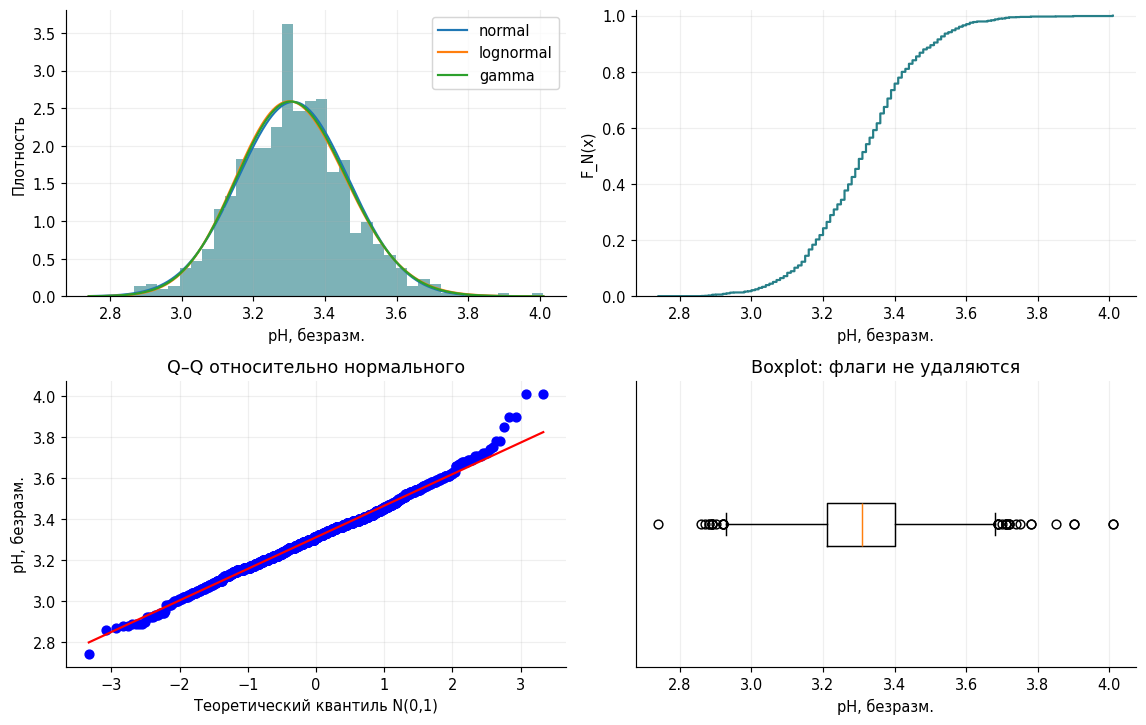

z: mean=2.86e-15, std(ddof=1)=1.000000; min–max: [0.0, 1.0]
Шапиро–Уилк:        p   p_Holm
0.000002 0.000002


In [7]:
eda('pH')


### Independence & Estimations
Связи с остальными показателями проверяются в общем блоке ниже. Здесь исследуется точность оценивания при повторных случайных отборах.

   mode     n    bias_mean  RMSE_mean   theory_SE     bias_var    RMSE_var
0    WR    20  0.000530304  0.0336414   0.0345111 -0.000218381  0.00885192
1    WR    50  0.000142404  0.0220668   0.0218267  0.000248835  0.00576107
2    WR   100  0.000210504   0.015573   0.0154338  0.000221297  0.00396981
3    WR   300  8.89043e-05 0.00873056  0.00891072  1.51818e-06   0.0022887
4    WR   800 -0.000271608 0.00543905  0.00545668  -2.0166e-05  0.00140227
5    WR  1500  9.12309e-05 0.00394909  0.00398499 -1.21542e-05  0.00102505
6   WOR    20    0.0010603  0.0345629   0.0343053  0.000243809  0.00893914
7   WOR    50 -0.000359996  0.0211261   0.0214895  6.80972e-05   0.0054872
8   WOR   100  0.000329904  0.0149996   0.0149481  2.65545e-05  0.00386164
9   WOR   300  0.000180738 0.00804121  0.00803395   1.0992e-05  0.00209291
10  WOR   800  0.000170229 0.00385102  0.00385845 -7.06269e-06 0.000994767
11  WOR  1500 -5.08241e-06 0.00100274 0.000991875   8.2735e-07 0.000254243


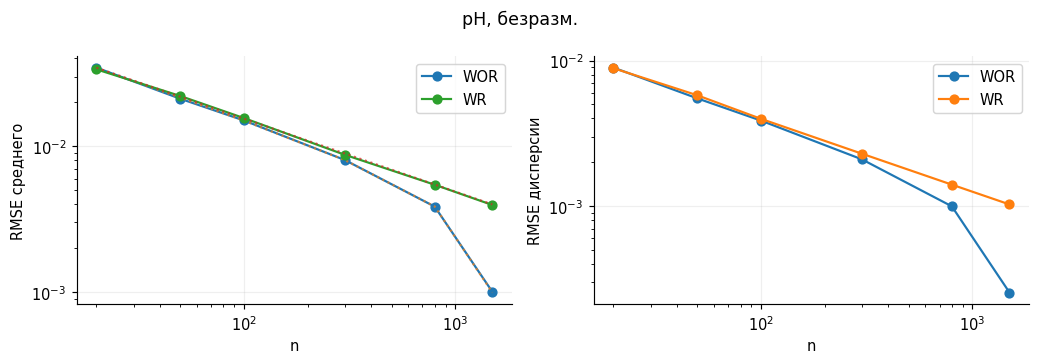

  mode    n  unique_rows   mean  population_mean  mean_error  median  population_median  variance  target_variance  CI_low  CI_high  covers
0   WR  300          274  3.316          3.31111   0.0048868    3.32               3.31  0.021111        0.0238203 3.29956  3.33244    True
1  WOR  300          300 3.3188          3.31111   0.0076868    3.32               3.31 0.0225899        0.0238352 3.30347  3.33413    True


In [8]:
estimations('pH', SEED + 1)


### Resume
Среднее близко к медиане; центральная часть напоминает колокол. Однако это не достаточное основание объявить распределение нормальным: тест и хвосты Q–Q нужно учитывать одновременно. Среднее pH не равно pH средней активности из-за нелинейности логарифма.

Средний pH равен 3.311, медиана — 3.31. При отборе с возвращением ошибка среднего RMSE уменьшается примерно с 0.0336 при n=20 до 0.00395 при n=1500. На большем числе проб средний pH этой таблицы оценивается точнее.

<a id="rv2"></a>
## Random Variable 02 — Остаточный сахар
### Description (природа события)
При выборе образца случайна концентрация оставшегося сахара. Различия исходного сырья и условий брожения дают правдоподобные причины вариации, но причинность этим набором не устанавливается. Формула $c=m/V$ требует неизвестной массы сахара конкретного выбранного образца.
### EDA & Distribution

       model     AIC                 parameters
1  lognormal 3969.77  (0.357332, 0.0, 2.340189)
2      gamma 4402.28  (6.299814, 0.0, 0.402997)
0     normal  5639.4       (2.538806, 1.409487)


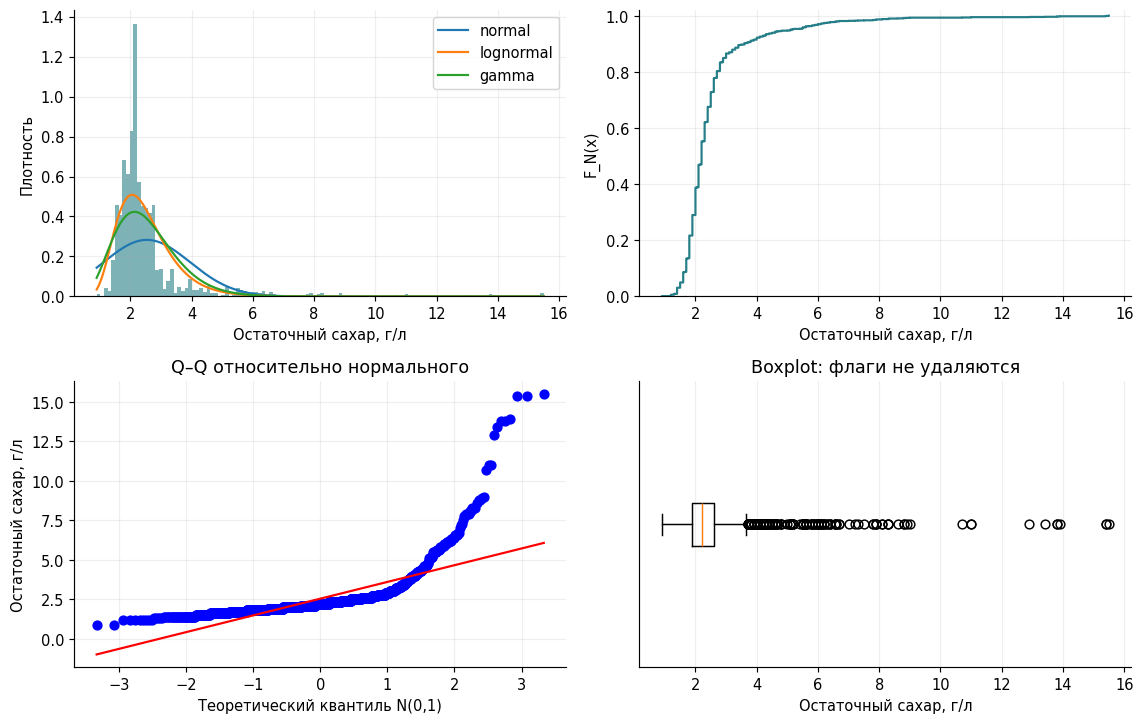

z: mean=-1.11e-16, std(ddof=1)=1.000000; min–max: [0.0, 1.0]
Шапиро–Уилк:            p       p_Holm
1.020162e-52 3.060485e-52


In [9]:
eda('residual sugar')


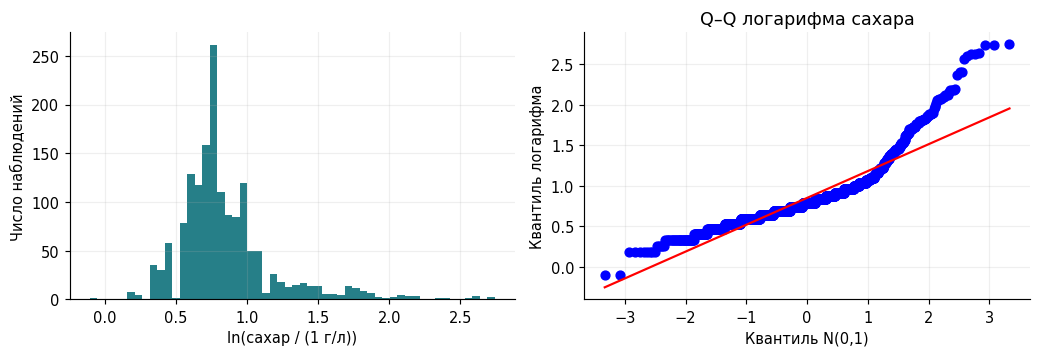

Диагностический p Шапиро для log(sugar): 5.471063007321477e-36


In [10]:
log_sugar = np.log(X['residual sugar'].to_numpy() / 1.0)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].hist(log_sugar, bins='fd', color='#267f88')
ax[0].set(xlabel='ln(сахар / (1 г/л))', ylabel='Число наблюдений')
stats.probplot(log_sugar, plot=ax[1])
ax[1].set(title='Q–Q логарифма сахара', xlabel='Квантиль N(0,1)', ylabel='Квантиль логарифма')
fig.tight_layout()
plt.show()
print('Диагностический p Шапиро для log(sugar):', stats.shapiro(log_sugar).pvalue)


### Independence & Estimations
Связи с остальными показателями проверяются в общем блоке ниже. Здесь исследуется точность оценивания при повторных случайных отборах.

   mode     n    bias_mean  RMSE_mean  theory_SE    bias_var  RMSE_var
0    WR    20     0.016672     0.3375   0.315171    0.144986   2.68756
1    WR    50  0.000456497   0.202107   0.199332  0.00332746   1.55292
2    WR   100     0.005879   0.139327   0.140949   0.0209733   1.07931
3    WR   300   0.00078833  0.0804133  0.0813768   0.0108015  0.646304
4    WR   800 -0.000940003  0.0502928  0.0498329  -0.0224133  0.381097
5    WR  1500     -0.00192  0.0364421  0.0363928  -0.0105504  0.284618
6   WOR    20    0.0062945   0.323834   0.313292   0.0770572   2.57547
7   WOR    50    0.0046825   0.195338   0.196252   0.0066193   1.50814
8   WOR   100   -0.0087605   0.137697   0.136513  -0.0164001   1.09491
9   WOR   300   0.00132766  0.0754209  0.0733697   0.0136102  0.582457
10  WOR   800 -0.000381378   0.035784  0.0352372 -0.00218296  0.276408
11  WOR  1500 -0.000404303  0.0091688 0.00905826 -0.00345996 0.0722299


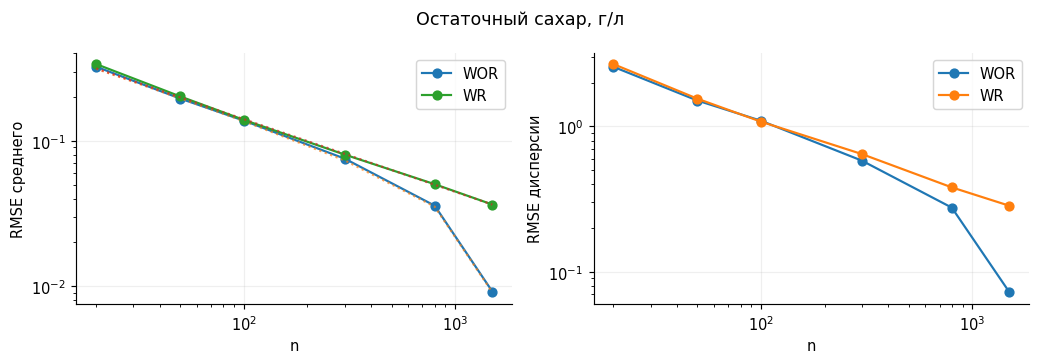

  mode    n  unique_rows    mean  population_mean  mean_error  median  population_median  variance  target_variance  CI_low  CI_high  covers
0   WR  300          277 2.72367          2.53881    0.184861     2.2                2.2    3.6743          1.98665 2.50675  2.94058    True
1  WOR  300          300   2.708          2.53881    0.169194     2.2                2.2   2.79007           1.9879 2.53763  2.87837    True


In [11]:
estimations('residual sugar', SEED + 2)


### Resume
Среднее выше медианы: редкие большие концентрации тянут его вверх. Поэтому вместе со средним важны медиана и IQR. Удалять правый хвост ради красивой нормальности нельзя. Логарифм сжимает хвост, но не гарантирует нормальность.

Среднее содержание сахара — 2.539 г/л, медиана — 2.2 г/л. Разница согласуется с длинным правым хвостом. При отборе с возвращением RMSE среднего уменьшается с 0.338 до 0.0364 г/л. Даже при большом n редкие высокие значения заметно влияют на оценку дисперсии.

<a id="rv3"></a>
## Random Variable 03 — Объёмное содержание спирта
### Description (природа события)
При выборе пробы случайно содержание этанола. Его связь с брожением не позволяет точно вычислить значение по одному остаточному сахару: неизвестны исходный состав и история процесса. Это положительная физически ограниченная величина, измеряемая в процентах по объёму.
### EDA & Distribution

       model     AIC                   parameters
1  lognormal  4621.9   (0.098869, 0.0, 10.371074)
2      gamma  4658.6  (100.313094, 0.0, 0.103905)
0     normal 4744.16        (10.422983, 1.065334)


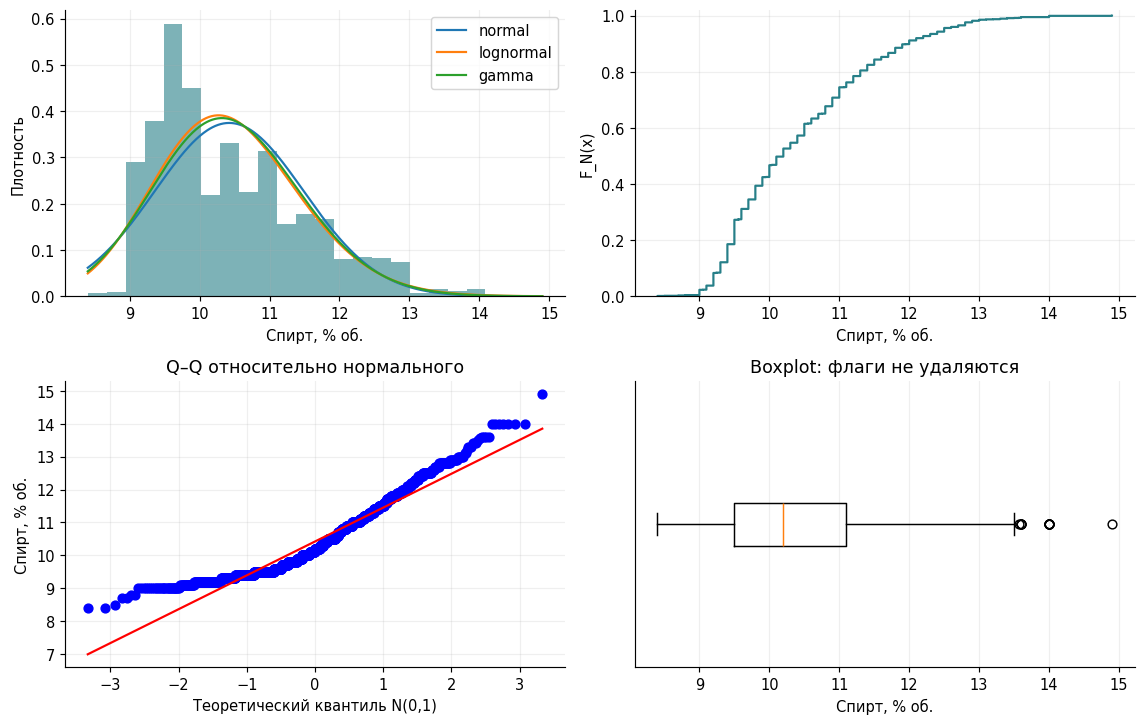

z: mean=7.11e-17, std(ddof=1)=1.000000; min–max: [0.0, 1.0]
Шапиро–Уилк:            p       p_Holm
6.644057e-27 1.328811e-26


In [12]:
eda('alcohol')


### Independence & Estimations
Связи с остальными показателями проверяются в общем блоке ниже. Здесь исследуется точность оценивания при повторных случайных отборах.

   mode     n    bias_mean  RMSE_mean  theory_SE     bias_var  RMSE_var
0    WR    20  -0.00381061   0.230613   0.238216    0.0157193  0.388941
1    WR    50  0.000376552   0.142109   0.150661   0.00741097  0.233737
2    WR   100  -0.00181111   0.102898   0.106533 -0.000627756  0.170435
3    WR   300  0.000984052   0.059577  0.0615071   0.00130555 0.0976253
4    WR   800  -0.00127359  0.0362776  0.0376653  -0.00100963 0.0590445
5    WR  1500  0.000584141  0.0275946  0.0275068   0.00042592 0.0426278
6   WOR    20  -0.00420978   0.241761   0.236796   -0.0115123  0.388755
7   WOR    50  -0.00268011    0.15227   0.148333   0.00320939   0.22861
8   WOR   100  -0.00376695   0.103407   0.103181  -0.00355705  0.160623
9   WOR   300  -0.00113417  0.0564142  0.0554551  -0.00144106 0.0894398
10  WOR   800 -0.000976885  0.0255182  0.0266334  -0.00156657 0.0427391
11  WOR  1500  0.000128208 0.00705355 0.00684651 -0.000133433 0.0111206


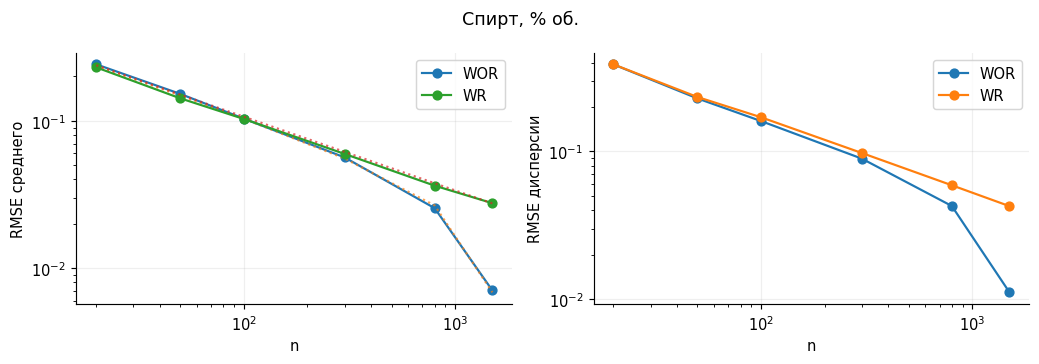

  mode    n  unique_rows    mean  population_mean  mean_error  median  population_median  variance  target_variance  CI_low  CI_high  covers
0   WR  300          272 10.4922           10.423   0.0692391    10.3               10.2   1.22787          1.13494 10.3668  10.6176    True
1  WOR  300          300 10.3899           10.423  -0.0330942    10.1               10.2   1.11362          1.13565 10.2823  10.4975    True


In [13]:
estimations('alcohol', SEED + 3)


### Resume
Содержание спирта несимметрично и округлено. Различия могут отражать технологию и состав, но данных для установления конкретных причин нет. Нормальная модель способна дать невозможные значения; положительные модели также не учитывают верхнюю физическую границу 100%.

Среднее содержание спирта — 10.423 % об., медиана — 10.2 % об. При отборе с возвращением RMSE среднего уменьшается с 0.231 до 0.0276 процентного пункта. Оба способа отбора дают более точные оценки при увеличении n.

<a id="dependence"></a>
## Парные зависимости и гипотезы
Независимость означает $P(A\cap B)=P(A)P(B)$ для любых событий, заданных двумя величинами. Чтобы проверить связь по всему диапазону, разобьём каждый показатель на четыре группы по квартилям и составим таблицу частот.

**H₀:** группы двух показателей независимы. **H₁:** зависимы.
При H₀ ожидаемое число в ячейке $E_{ij}=n_{i\cdot}n_{\cdot j}/N$. Сравниваем его с наблюдаемым $O_{ij}$:
$$\chi^2=\sum_{i,j}\frac{(O_{ij}-E_{ij})^2}{E_{ij}}.$$
Число степеней свободы равно $(r-1)(c-1)$. Используем обычный χ²-критерий и проверяем достаточность частот. Поправка Холма учитывает три парные проверки; уровень значимости 0.05.

Если исходные величины независимы, их группы тоже независимы. Поэтому отклонение H₀ даёт свидетельство связи исходных показателей. Неотклонение не доказывает независимость. Pearson и Spearman описывают силу линейной и монотонной связи. Проверка без полных повторов показывает чувствительность к дублям. Независимость самих образцов неизвестна, поэтому статистические выводы за пределами таблицы условны.


Все строки
                x               y    Pearson  Spearman    chi2  df           p  min_expected      p_Holm  reject_0.05
0              pH  residual sugar -0.0856524 -0.089971 46.0944   9 5.78387e-07       85.9193 1.15677e-06         True
1              pH         alcohol   0.205633  0.179932 67.2673   9  5.2158e-11       91.2439 1.56474e-10         True
2  residual sugar         alcohol  0.0420754  0.116548 33.8656   9  9.4297e-05       83.6992  9.4297e-05         True
Без полных повторов
                x               y    Pearson   Spearman    chi2  df           p  min_expected      p_Holm  reject_0.05
0              pH  residual sugar -0.0831435 -0.0915427 36.4102   9 3.35222e-05       73.6439 6.70443e-05         True
1              pH         alcohol   0.213418   0.183005 48.9962   9 1.66256e-07       73.6439 4.98767e-07         True
2  residual sugar         alcohol  0.0632811   0.112205 30.6443   9 0.000340614       69.3517 0.000340614         True


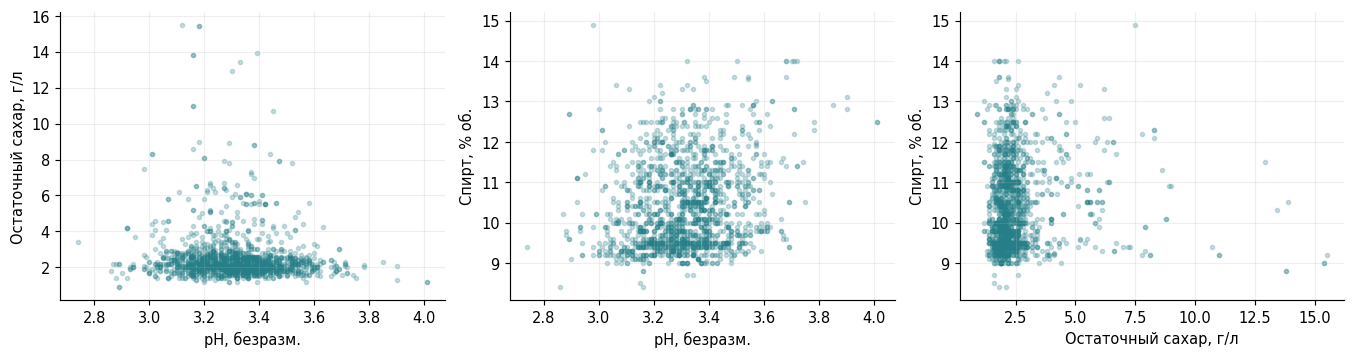

In [14]:
def dependence(data):
    out = []
    for a, b in combinations(cols, 2):
        a_group = pd.qcut(data[a], 4, duplicates='drop')
        b_group = pd.qcut(data[b], 4, duplicates='drop')
        counts = pd.crosstab(a_group, b_group)
        chi, p, dof, expected = stats.chi2_contingency(counts, correction=False)
        assert expected.min() >= 5 and counts.to_numpy().min() >= 5
        out.append({'x': a, 'y': b, 'Pearson': stats.pearsonr(data[a], data[b]).statistic, 'Spearman': stats.spearmanr(data[a], data[b]).statistic, 'chi2': chi, 'df': dof, 'p': p, 'min_expected': expected.min()})
    out = pd.DataFrame(out)
    out['p_Holm'] = holm(out.p)
    out['reject_0.05'] = out.p_Holm < 0.05
    return out
relations = dependence(df)
relations_unique = dependence(df.drop_duplicates())
print('Все строки')
table(relations)
print('Без полных повторов')
table(relations_unique)
fig, axs = plt.subplots(1, 3, figsize=(13, 3.5))
for ax, (a, b) in zip(axs, combinations(cols, 2)):
    ax.scatter(X[a], X[b], s=8, alpha=0.25, color='#267f88')
    ax.set(xlabel=labels[a], ylabel=labels[b])
fig.tight_layout()
plt.show()


### Интерпретация связей
Величина эффекта важнее одного p-значения: маленькая корреляция может оказаться значимой при большом числе строк. Даже выявленная связь сахара и спирта не означает, что можно восстановить содержание спирта одной формулой по остаточному сахару. Нельзя трактовать межобразцовую корреляцию как кинетику брожения одной пробы.

<a id="resume1"></a>
## Lab resume
### Численные итоги первого спринта

In [15]:
final1 = summary[['mean', 'median', 'std_ddof1', 'skew']].copy()
final1['normality_p_Holm'] = normality.set_index('variable').p_Holm
final1['best_AIC_model'] = [fits[c].iloc[0]['model'] for c in final1.index]
table(final1)
for c in cols:
    r = estimation_results[c]
    for mode in ['WR', 'WOR']:
        z = r[r['mode'] == mode]
        print(f'{c}, {mode}: RMSE среднего {z.iloc[0].RMSE_mean:.5g} → {z.iloc[-1].RMSE_mean:.5g}; RMSE дисперсии {z.iloc[0].RMSE_var:.5g} → {z.iloc[-1].RMSE_var:.5g}')


                  mean  median  std_ddof1     skew  normality_p_Holm best_AIC_model
pH             3.31111    3.31   0.154386 0.193683       1.71224e-06      lognormal
residual sugar 2.53881     2.2    1.40993  4.54066       3.06048e-52      lognormal
alcohol         10.423    10.2    1.06567 0.860829       1.32881e-26      lognormal
pH, WR: RMSE среднего 0.033641 → 0.0039491; RMSE дисперсии 0.0088519 → 0.001025
pH, WOR: RMSE среднего 0.034563 → 0.0010027; RMSE дисперсии 0.0089391 → 0.00025424
residual sugar, WR: RMSE среднего 0.3375 → 0.036442; RMSE дисперсии 2.6876 → 0.28462
residual sugar, WOR: RMSE среднего 0.32383 → 0.0091688; RMSE дисперсии 2.5755 → 0.07223
alcohol, WR: RMSE среднего 0.23061 → 0.027595; RMSE дисперсии 0.38894 → 0.042628
alcohol, WOR: RMSE среднего 0.24176 → 0.0070535; RMSE дисперсии 0.38876 → 0.011121


### Выводы первого спринта
1. Все три величины имеют ненулевой разброс; они случайны относительно заданной процедуры выбора образца. Данные не позволяют отделить биохимическую вариативность от погрешности измерения.
2. Нормальность отвергается для всех трёх показателей в принятой диагностической модели. pH ближе к симметричной форме, сахар имеет выраженный правый хвост. Стандартизация не устраняет эту форму.
3. Сравнение AIC ранжирует три приближения, но не устанавливает «истинное распределение». Эмпирическое распределение сохраняет наблюдаемые частоты и хвост без подгонки семейства.
4. Рост объёма отбора уменьшает RMSE оценок среднего и дисперсии. Без возвращения ошибка среднего дополнительно уменьшается при приближении к переписи. Сравнение среднего и медианы важно для асимметричного сахара.
5. Для всех трёх пар независимость отвергается при принятых предпосылках, в том числе после удаления полных повторов. При этом связи слабы: коэффициенты Спирмена примерно −0.090, 0.180 и 0.117; значимость не означает сильную связь или причинность.

Вероятность сахара выше 3 г/л в доступной совокупности равна 215/1599 ≈ 13.45%. Среди образцов со спиртом выше 11 % об. она равна 73/408 ≈ 17.89%. Для этой таблицы знание содержания спирта меняет вероятность выбранного события.

### cat_mark_table
Официальные `cat_id` и веса не предоставлены. Ниже **локальные обозначения**, а не заявленные преподавателем баллы; `coeff` не заполняется до получения рубрики.

| cat_id | notebook_link | coeff | comment |
|---|---|---|---|
| local_S1_data | [Данные](#data) | — | 1 датасет, 3 химические величины |
| local_S1_rv | [Описание](#rv1) | — | Случайный выбор образца, ограничения |
| local_S1_eda | [EDA](#rv2) | — | Статистики, ECDF, Q–Q, boxplot, масштабирование |
| local_S1_estimations | [Оценки](#rv3) | — | WR/WOR, RMSE среднего и дисперсии, интервалы |
| local_S1_hypotheses | [Связи](#dependence) | — | χ², Holm, чувствительность |
| local_S1_resume | [Итоги](#resume1) | — | Численные выводы и пределы обобщения |

<a id="references"></a>
## Литература
1. Cortez P., Cerdeira A., Almeida F., Matos T., Reis J. **Wine Quality [Dataset]**. UCI, 2009. [DOI 10.24432/C56S3T](https://doi.org/10.24432/C56S3T). [ZIP исходных данных](https://archive.ics.uci.edu/static/public/186/wine+quality.zip). Дата получения: 11.10.2026. Лицензия CC BY 4.0; исходные байты проверяются SHA256.
2. Cortez P. et al. **Modeling wine preferences by data mining from physicochemical properties**. Decision Support Systems, 47(4), 547–553, 2009. [DOI 10.1016/j.dss.2009.05.016](https://doi.org/10.1016/j.dss.2009.05.016). Библиографический источник датасета. Полная статья не использовалась для переноса готовой аналитики; результаты её моделей здесь не воспроизводятся и не заявляются проверенными.
3. Nugent R. **Using chemical measurements to identify the quality of Wine**. CMU, 2016. [Описание переменных](https://www.stat.cmu.edu/~rnugent/PCMI2016/WineQuality.pdf). Использовано для единиц выбранных показателей.
4. SciPy. [Shapiro–Wilk](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.shapiro.html), [χ² независимости](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.chi2_contingency.html), [goodness_of_fit](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.goodness_of_fit.html). Документация методов и ограничений; последний метод не запускался, приведён для альтернативной проверки семейства с оценкой параметров.